# Đánh giá theo kịch bản sử dụng nghiệp vụ

**Câu hỏi:** nếu CRM chỉ có thể ưu tiên một phần household mỗi tuần, mô hình propensity xác định nhóm có tỷ lệ mua được ghi nhận cao hơn quy tắc recency đến mức nào?

Notebook dùng validation để khảo sát POC, không đọc nhãn test. Mỗi cutoff là một lần ra quyết định, một household có thể xuất hiện nhiều tuần. Các mức ngân sách, chi phí và biên lợi nhuận dưới đây là **kịch bản giả định**, không phải thông tin đã được công ty xác nhận.

## 1. Dữ liệu và baseline cùng thời điểm huấn luyện

Ứng viên là pipeline LightGBM + chu kỳ đã cố định trong notebook calibration, fit model trên cutoff đến 439. Để so sánh quy tắc recency ở cùng thời điểm, tỷ lệ mua của từng nhóm recency cũng được học trên các cutoff train đến 439. Không dùng label validation để tính tỷ lệ baseline. Bảng dự báo cố định được lọc chỉ lấy validation và nối theo household–cutoff.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if ROOT.name == 'research' and ROOT.parent.name == 'notebooks': ROOT = ROOT.parent
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from propensity_v2.prepared_data import load_prepared_split
DATA=ROOT/'artifacts'/'data_preparation'; OUT=ROOT/'artifacts'/'research'/'business_scenarios_poc'
train,features=load_prepared_split(DATA,'train');validation,vfeatures=load_prepared_split(DATA,'validation')
assert features==vfeatures
pred=pd.read_parquet(ROOT/'artifacts'/'calibration_final_poc'/'predictions.parquet',
                     filters=[('split','=','validation'),('feature_set','=','18 + chu kỳ')])
frame=validation.merge(pred,on=['household_key','snapshot_day'],how='left',validate='one_to_one',suffixes=('','_saved'))
assert len(frame)==len(validation) and frame.probability.notna().all()
assert frame.target_any_basket.eq(frame.target_any_basket_saved).all()
bins=[-1,7,14,30,60,90,np.inf]; labels=['0–7','8–14','15–30','31–60','61–90','91+']
fit=train.loc[train.snapshot_day.le(439)].copy()
fit['recency_group']=pd.cut(fit.recency_days,bins=bins,labels=labels)
rates=fit.groupby('recency_group',observed=False).target_any_basket.agg(['size','mean'])
rates['probability']=rates['mean'].fillna(fit.target_any_basket.mean())
frame['recency_group']=pd.cut(frame.recency_days,bins=bins,labels=labels)
frame['recency_probability']=frame.recency_group.map(rates.probability).astype(float)
assert frame.recency_probability.notna().all()
print('Validation:',len(frame),'household-snapshot | Baseline fit:',len(fit),'household-snapshot')
display(rates)

Validation: 27480 household-snapshot | Baseline fit: 94862 household-snapshot
                size      mean  probability
recency_group                              
0–7            53135  0.705561     0.705561
8–14           12337  0.485288     0.485288
15–30          11137  0.352159     0.352159
31–60           7143  0.204116     0.204116
61–90           3470  0.137752     0.137752
91+             7640  0.065445     0.065445


## 2. Năng lực liên hệ 5%, 10% hoặc 20%

Trong từng cutoff, chọn `ceil(tỷ lệ × số household)` theo điểm. Với đồng điểm tại ngưỡng, tính số household mua **kỳ vọng** nếu chọn ngẫu nhiên trong nhóm đồng điểm; không dùng nhãn để phá hòa. Tổng lượt mua kỳ vọng được chia cho tổng suất tiếp cận; lift so với tỷ lệ mua chung có trọng số theo cùng số suất của từng cutoff.

Chênh lệch số lượt mua quan sát giữa hai nhóm ưu tiên phản ánh **khả năng xếp hạng**, không phải số giao dịch tăng thêm do gửi thông điệp. Các nhóm được chọn có thể giao nhau; không giả định họ là hai nhóm độc lập.

In [2]:
def top_expected(y,p,fraction):
    y=np.asarray(y,dtype=float);p=np.asarray(p,dtype=float)
    k=int(np.ceil(fraction*len(y)));threshold=np.partition(p,len(p)-k)[len(p)-k]
    higher=p>threshold;tied=p==threshold;slots=k-int(higher.sum())
    positives=y[higher].sum()+slots*y[tied].mean()
    return {'k':k,'expected_buyers':positives,'tie_count':int(tied.sum()),'tie_slots':slots,'prevalence':y.mean()}
weekly=[]
for cutoff,g in frame.groupby('snapshot_day',sort=True):
    for fraction in [.05,.10,.20]:
        for method,col in [('Recency','recency_probability'),('LightGBM + chu kỳ','probability')]:
            weekly.append({'snapshot_day':int(cutoff),'capacity':fraction,'method':method,**top_expected(g.target_any_basket,g[col],fraction)})
weekly=pd.DataFrame(weekly)
weekly['expected_random_buyers']=weekly.k*weekly.prevalence
summary=(weekly.groupby(['capacity','method'],as_index=False)
         .agg(cutoffs=('snapshot_day','nunique'),contacts=('k','sum'),expected_buyers=('expected_buyers','sum'),
              random_buyers=('expected_random_buyers','sum')))
summary['purchase_rate_expected']=summary.expected_buyers/summary.contacts
summary['lift_vs_random']=summary.expected_buyers/summary.random_buyers
display(summary)
wide=summary.pivot(index='capacity',columns='method',values='expected_buyers')
wide['chênh lệch lượt mua dự kiến khi xếp hạng']=wide['LightGBM + chu kỳ']-wide['Recency']
display(wide)

,capacity,method,cutoffs,contacts,expected_buyers,random_buyers,purchase_rate_expected,lift_vs_random
0,0.05,LightGBM + chu kỳ,11,1375,1353.000000,741.639610,0.984000,1.824336
1,0.05,Recency,11,1375,973.731461,741.639610,0.708168,1.312944
2,0.10,LightGBM + chu kỳ,11,2750,2656.000000,1483.279220,0.965818,1.790627
3,0.10,Recency,11,2750,1947.462921,1483.279220,0.708168,1.312944
4,0.20,LightGBM + chu kỳ,11,5500,5125.000000,2966.558441,0.931818,1.727591
5,0.20,Recency,11,5500,3894.925843,2966.558441,0.708168,1.312944


method,LightGBM + chu kỳ,Recency,chênh lệch lượt mua dự kiến khi xếp hạng
capacity,,,
0.05,1353.0,973.731461,379.268539
0.10,2656.0,1947.462921,708.537079
0.20,5125.0,3894.925843,1230.074157


## 3. Tính ổn định theo tuần

Chênh lệch là tỷ lệ mua kỳ vọng của nhóm mô hình trừ tỷ lệ của nhóm recency, tính trên cùng cutoff và cùng ngân sách. Đường này cho biết mô hình có xếp hạng tốt hơn ở những tuần nào; không phải tác động nhân quả hoặc khoảng tin cậy.

capacity,0.05,0.1,0.2
snapshot_day,,,
551,27.872241,27.072241,23.272241
558,25.321127,24.521127,19.921127
565,28.631579,24.631579,21.831579
572,24.753265,25.553265,23.153265
579,30.830511,28.430511,23.830511
586,25.776896,23.376896,21.376896
593,28.696896,25.496896,22.096896
600,28.064955,27.664955,23.864955
607,26.596268,23.396268,20.996268


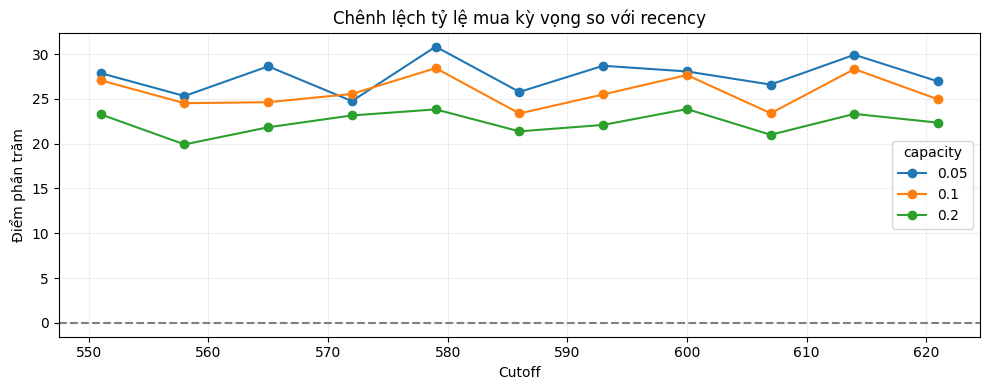

In [3]:
weekly['precision_expected']=weekly.expected_buyers/weekly.k
comparison=weekly.pivot(index=['snapshot_day','capacity'],columns='method',values='precision_expected').reset_index()
comparison['delta_pp']=(comparison['LightGBM + chu kỳ']-comparison['Recency'])*100
display(comparison.pivot(index='snapshot_day',columns='capacity',values='delta_pp'))
ax=comparison.pivot(index='snapshot_day',columns='capacity',values='delta_pp').plot(marker='o',figsize=(10,4))
ax.axhline(0,color='gray',linestyle='--');ax.set(title='Chênh lệch tỷ lệ mua kỳ vọng so với recency',xlabel='Cutoff',ylabel='Điểm phần trăm');ax.grid(alpha=.2);plt.tight_layout();plt.show()

## 4. Phân biệt propensity với giá trị tăng thêm

Muốn quyết định có liên hệ hay gửi ưu đãi, cần biết **uplift**: chênh lệch xác suất mua khi được liên hệ và khi không được liên hệ. Propensity ở các phần trên không cung cấp chênh lệch đó.

Với mô hình giả định đơn giản, lợi nhuận kỳ vọng trên mỗi liên hệ = `uplift × lợi nhuận đóng góp ròng cho mỗi giao dịch tăng thêm − chi phí trên mỗi liên hệ`. Điểm hòa vốn là `chi phí / lợi nhuận đóng góp ròng`. Bảng dưới đây chỉ là phép tính minh họa; không dùng lift propensity làm uplift, không tính chi phí chiến dịch cố định hay các tác động dài hạn.

In [4]:
illustrations=[]
for cost in [.10,.50,1.00]:
    for margin in [5.,10.,20.]:
        illustrations.append({'chi phí/liên hệ (USD, giả định)':cost,
                              'lợi nhuận ròng/giao dịch tăng thêm (USD, giả định)':margin,
                              'uplift hòa vốn (điểm %)':100*cost/margin,
                              'có thể hòa vốn nếu uplift ≤ 100%':cost/margin<=1})
illustrations=pd.DataFrame(illustrations);display(illustrations)

,"chi phí/liên hệ (USD, giả định)","lợi nhuận ròng/giao dịch tăng thêm (USD, giả định)",uplift hòa vốn (điểm %),có thể hòa vốn nếu uplift ≤ 100%
0,0.1,5.0,2.0,True
1,0.1,10.0,1.0,True
2,0.1,20.0,0.5,True
3,0.5,5.0,10.0,True
4,0.5,10.0,5.0,True
5,0.5,20.0,2.5,True
6,1.0,5.0,20.0,True
7,1.0,10.0,10.0,True
8,1.0,20.0,5.0,True


**Kết quả mô tả:** Ở năng lực 10%, 2.750 suất ưu tiên qua 11 cutoff có tỷ lệ mua ghi nhận ước tính 96,58% theo xếp hạng LightGBM và 70,82% theo recency có xử lý đồng điểm kỳ vọng. Đây là lượt household–cutoff, không phải household riêng biệt; chênh lệch không đo giao dịch do liên hệ tạo ra. Nếu chi phí là 0,50 USD mỗi liên hệ và lợi nhuận ròng cho một giao dịch tăng thêm là 10 USD, uplift hòa vốn theo công thức minh họa là 5 điểm phần trăm; cả hai con số đều chỉ là giả định.


## 5. Bàn giao và bước xác minh

Trước khi dùng trong thực tế, cần chốt số household có thể liên hệ, chi phí, lợi nhuận đóng góp, ưu đãi, thời gian đo và quy tắc liên hệ lặp. Nếu muốn đo tác động tăng thêm, cần nhóm đối chứng ngẫu nhiên hoặc thiết kế đánh giá phù hợp để ước lượng uplift. Test của project đã từng được xem xét; cần dữ liệu tương lai chưa dùng trong phát triển để xác nhận khả năng tổng quát hóa.

In [5]:
OUT.mkdir(parents=True,exist_ok=True)
rates.to_csv(OUT/'recency_training_rates.csv',encoding='utf-8-sig')
summary.to_csv(OUT/'capacity_scenarios.csv',index=False,encoding='utf-8-sig')
weekly.to_csv(OUT/'weekly_capacity_scenarios.csv',index=False,encoding='utf-8-sig')
comparison.to_csv(OUT/'weekly_ranking_difference.csv',index=False,encoding='utf-8-sig')
illustrations.to_csv(OUT/'illustrative_break_even.csv',index=False,encoding='utf-8-sig')
print('Đã lưu:',OUT)

Đã lưu: artifacts\business_scenarios_poc
